In [2]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


(120, 120) RGB


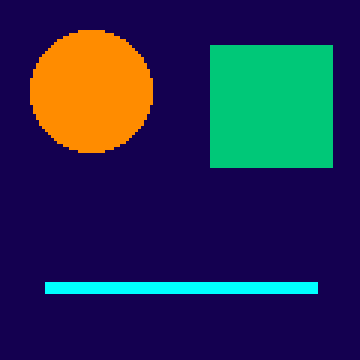

In [10]:
from PIL import Image, ImageDraw

img = Image.new("RGB", (120, 120), (20, 0, 80))
draw = ImageDraw.Draw(img)

draw.ellipse([10, 10, 50, 50], fill=(255, 140, 0))          # figura 1: círculo naranja (arriba izquierda)
draw.rectangle([70, 15, 110, 55], fill=(0, 200, 120))       # figura 2: rectángulo verde (arriba derecha)
draw.line([15, 95, 105, 95], fill=(0, 255, 255), width=4)   # figura 3: línea cian (abajo)

print(img.size, img.mode)
img.save("mi_imagen.png")

img.resize((360, 360), Image.NEAREST)   # vista ampliada en Jupyter

Formato: PNG
Fondo      (5, 60) -> (20, 0, 80)
Figura 1   (30, 30) -> (255, 140, 0)
Figura 2   (90, 35) -> (0, 200, 120)


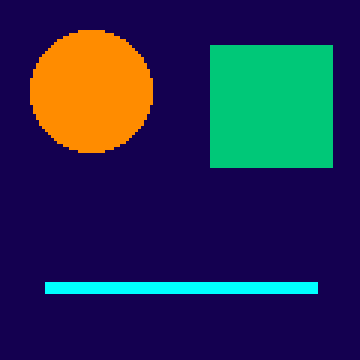

In [17]:
from PIL import Image

# Reabrir la imagen guardada
img2 = Image.open("mi_imagen.png")

# Verificar el formato
print("Formato:", img2.format)   # debe imprimir PNG

# Coordenadas exactas que se usan (anótalas para la Tarea 3)
p_fondo     = (5, 60)     # fondo morado
p_figura1   = (30, 30)    # centro del círculo naranja
p_figura2   = (90, 35)    # centro del rectángulo verde

# Imprimir el valor de cada píxel
print("Fondo     ", p_fondo,   "->", img2.getpixel(p_fondo))
print("Figura 1  ", p_figura1, "->", img2.getpixel(p_figura1))
print("Figura 2  ", p_figura2, "->", img2.getpixel(p_figura2))
img2.resize((360, 360), Image.NEAREST)

Original: (120, 120)
convert('L')  -> (120, 120) L
rotate(90)    -> (120, 120)
resize mitad  -> (60, 60)
flip vertical -> (120, 120)


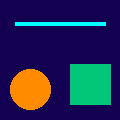

In [15]:
from PIL import Image

# Reabrir la imagen guardada
img2 = Image.open("mi_imagen.png")
print("Original:", img2.size)

# 1) Convertir a escala de grises
gris = img2.convert("L")
print("convert('L')  ->", gris.size, gris.mode)

# 2) Rotar 90 grados (expand=True ajusta el lienzo al nuevo tamaño)
rotada = img2.rotate(90, expand=True)
print("rotate(90)    ->", rotada.size)

# 3) Redimensionar a la mitad del tamaño original
mitad = img2.resize((img2.width // 2, img2.height // 2))
print("resize mitad  ->", mitad.size)

# 4) Volteo vertical (arriba <-> abajo)
volteada = img2.transpose(Image.FLIP_TOP_BOTTOM)
print("flip vertical ->", volteada.size)
volteada

Factor 0.5 -> (127, 70, 0)
Píxel (30, 30) ANTES  (original):       (255, 140, 0)
Píxel (30, 30) DESPUÉS (factor 2.5 ): (255, 255, 0)
Canal R: ya estaba en 255, sigue saturado
Canal G: recortado en 255 (pasó de 140 a 255)
Canal B: en 0 (multiplicar 0 por cualquier factor da 0)


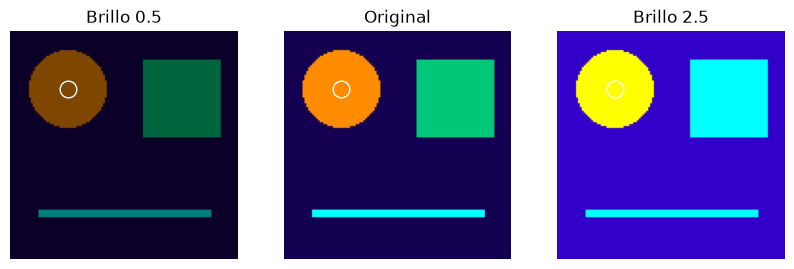

In [22]:
from PIL import Image, ImageEnhance, ImageFilter

# Reabrir la imagen y asegurar modo RGB
img2 = Image.open("mi_imagen.png").convert("RGB")

# Dos factores de brillo distintos
factor_menor = 0.5   # menor a 1.0 -> oscurece
factor_mayor = 2.5   # mayor a 2.0 -> aclara mucho

oscura = ImageEnhance.Brightness(img2).enhance(factor_menor)
clara  = ImageEnhance.Brightness(img2).enhance(factor_mayor)

# Píxel de una figura de color saturado (centro del círculo naranja)
p = (30, 30)
antes   = img2.getpixel(p)
despues = clara.getpixel(p)

print("Factor", factor_menor, "->", oscura.getpixel(p))
print("Píxel", p, "ANTES  (original):      ", antes)
print("Píxel", p, "DESPUÉS (factor", factor_mayor, "):", despues)

# Verificar canales recortados (sin escribir los valores a mano)
nombres = ["R", "G", "B"]
for nombre, a, d in zip(nombres, antes, despues):
    if d == 255 and a < 255:
        print(f"Canal {nombre}: recortado en 255 (pasó de {a} a 255)")
    elif d == 255:
        print(f"Canal {nombre}: ya estaba en 255, sigue saturado")
    elif d == 0:
        print(f"Canal {nombre}: en 0 (multiplicar 0 por cualquier factor da 0)")
    else:
        print(f"Canal {nombre}: sin recorte ({a} -> {d})")
    import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, im, t in zip(ejes, [oscura, img2, clara],
                     [f"Brillo {factor_menor}", "Original", f"Brillo {factor_mayor}"]):
    ax.imshow(im)
    ax.plot(p[0], p[1], "wo", markerfacecolor="none", markersize=12)  # marca el píxel medido
    ax.set_title(t)
    ax.axis("off")
plt.show()

In [19]:
from PIL import Image, ImageFilter

# Reabrir la imagen original en RGB
img2 = Image.open("mi_imagen.png").convert("RGB")

# 1) Desenfoque gaussiano (el radio lo eliges tú; mayor radio = más borroso)
borrosa = img2.filter(ImageFilter.GaussianBlur(radius=3))
borrosa.save("mi_imagen_blur.png")

# 2) Detección de bordes
bordes = img2.filter(ImageFilter.FIND_EDGES)
bordes.save("mi_imagen_bordes.png")

print("Blur  :", borrosa.size, borrosa.mode)
print("Bordes:", bordes.size, bordes.mode)

Blur  : (120, 120) RGB
Bordes: (120, 120) RGB


Blur  : (120, 120) RGB
Bordes: (120, 120) RGB


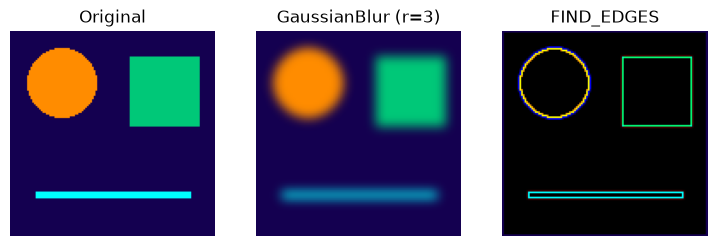

In [26]:
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

# Reabrir la imagen original en RGB
img2 = Image.open("mi_imagen.png").convert("RGB")

# 1) Desenfoque gaussiano (radio elegido por ti)
borrosa = img2.filter(ImageFilter.GaussianBlur(radius=3))
borrosa.save("mi_imagen_blur.png")

# 2) Detección de bordes
bordes = img2.filter(ImageFilter.FIND_EDGES)
bordes.save("mi_imagen_bordes.png")

print("Blur  :", borrosa.size, borrosa.mode)
print("Bordes:", bordes.size, bordes.mode)

# Para ver los resultados
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(ejes, [img2, borrosa, bordes],
                     ["Original", "GaussianBlur (r=3)", "FIND_EDGES"]):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis("off")
plt.show()